# 04 — Avaliação e Interpretação

Neste notebook, é testado o modelo final (Random Forest) na base de teste que deixamos reservada. Analise da Matriz de Confusão, a Curva ROC-AUC e a Importância das Variáveis (Feature Importance) para entender o que o modelo aprendeu e como essas métricas se traduzem na prática para a decisão de concessão de crédito.

In [1]:
from google.colab import drive
from pathlib import Path
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns
import numpy as np

# Semente fixa
RANDOM_STATE = 42

# 1. Montar o Google Drive
drive.mount('/content/drive')

# 2. Caminho oficial e busca dinâmica do dataset_tratado.csv
BASE_DIR = Path("/content/drive/MyDrive/Pós Tech/Tech Challange/BaseDados Fase2")
OFFICIAL_PATH = BASE_DIR / "processed" / "dataset_tratado.csv"
LOCAL_PATH = Path("dataset_tratado.csv")
TARGET = "TARGET"

pd.set_option("display.max_columns", None)

if OFFICIAL_PATH.exists():
    df = pd.read_csv(OFFICIAL_PATH)
    print("✓ Dataset carregado do caminho oficial no Google Drive!")
elif LOCAL_PATH.exists():
    df = pd.read_csv(LOCAL_PATH)
    print("✓ Dataset carregado do diretório local do Colab!")
else:
    drive_root = Path('/content/drive/MyDrive')
    encontrados = list(drive_root.rglob('dataset_tratado.csv'))
    if encontrados:
        df = pd.read_csv(encontrados[0])
        print(f"✓ Dataset localizado via busca dinâmica em: {encontrados[0]}")
    else:
        raise FileNotFoundError("Arquivo 'dataset_tratado.csv' não encontrado.")

print(f"✓ Formato do Dataset Carregado: {df.shape[0]} linhas × {df.shape[1]} colunas")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
✓ Dataset localizado via busca dinâmica em: /content/drive/MyDrive/Pós Tech/Tech Challange/BaseDadosFase2/processed/dataset_tratado.csv
✓ Formato do Dataset Carregado: 36457 linhas × 57 colunas


## **1. Métricas no Conjunto de Teste**

Treinamento do *Random Forest* no conjunto de treino completo (80%) com avaliação direta no conjunto de teste retido (20%), preservando as 55 variáveis preditivas.

In [2]:
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, roc_auc_score, confusion_matrix, ConfusionMatrixDisplay, roc_curve

# Separar X e y
X = df.drop(columns=[TARGET, 'ID'], errors='ignore')
y = df[TARGET]

# Split Treino / Teste (80/20) estratificado
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, stratify=y, random_state=RANDOM_STATE
)

# Treinar o modelo campeão (Random Forest)
modelo_rf = RandomForestClassifier(
    n_estimators=300,
    max_depth=12,
    class_weight='balanced',
    random_state=RANDOM_STATE,
    n_jobs=-1
)
modelo_rf.fit(X_train, y_train)

# Predições no conjunto de teste
y_pred = modelo_rf.predict(X_test)
y_proba = modelo_rf.predict_proba(X_test)[:, 1]

# Métricas
auc_score = roc_auc_score(y_test, y_proba)

print("=== RELATÓRIO DE DESEMPENHO NO CONJUNTO DE TESTE ===")
print(classification_report(y_test, y_pred, target_names=['Bom Pagador (0)', 'Mau Pagador (1)']))
print(f"ROC-AUC Score Final no Teste: {auc_score:.4f}")

=== RELATÓRIO DE DESEMPENHO NO CONJUNTO DE TESTE ===
                 precision    recall  f1-score   support

Bom Pagador (0)       0.99      0.97      0.98      7169
Mau Pagador (1)       0.17      0.31      0.22       123

       accuracy                           0.96      7292
      macro avg       0.58      0.64      0.60      7292
   weighted avg       0.97      0.96      0.97      7292

ROC-AUC Score Final no Teste: 0.6996


## **2. Justificativa das Métricas**

### Por que a Acurácia pura é enganosa?
Com uma base onde 98,31% dos clientes são bons pagadores, um modelo ingênuo que aprovasse todas as solicitações obteria 98,3% de acurácia, mas falharia em 100% no objetivo de conter a inadimplência.

### Análise do Custo do Erro Financeiro:
* **Falso Negativo (Aprovar um mau pagador):** É o erro de **maior custo para o banco**, pois se traduz em calote/inadimplência direta e necessidade de provisionamento de PDD (*Provisão para Devedores Duvidosos*).
* **Falso Positivo (Recusar um bom pagador):** Gera custo de oportunidade (perda da taxa/juros do cartão), mas preserva o capital principal da instituição.

**Foco Estratégico:** Priorizamos o **Recall da classe 1 (Maus Pagadores)** e a métrica **ROC-AUC**, assegurando que o banco maximize a captura de clientes de risco sem bloquear demasiadamente a concessão de crédito.

# **3. Matriz de confusão**

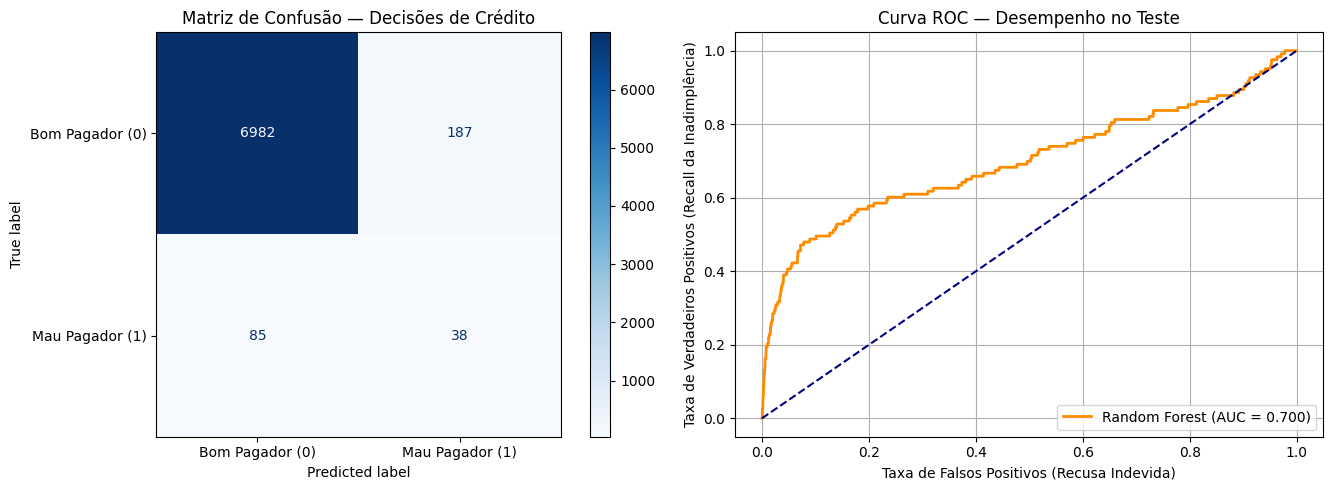

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Matriz de Confusão
cm = confusion_matrix(y_test, y_pred)
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=['Bom Pagador (0)', 'Mau Pagador (1)'])
disp.plot(cmap='Blues', ax=axes[0])
axes[0].set_title("Matriz de Confusão — Decisões de Crédito")
axes[0].grid(False)

# Curva ROC
fpr, tpr, _ = roc_curve(y_test, y_proba)
axes[1].plot(fpr, tpr, label=f'Random Forest (AUC = {auc_score:.3f})', color='darkorange', lw=2)
axes[1].plot([0, 1], [0, 1], color='navy', linestyle='--')
axes[1].set_xlabel('Taxa de Falsos Positivos (Recusa Indevida)')
axes[1].set_ylabel('Taxa de Verdadeiros Positivos (Recall da Inadimplência)')
axes[1].set_title('Curva ROC — Desempenho no Teste')
axes[1].legend(loc="lower right")
axes[1].grid(True)

plt.tight_layout()
plt.show()

# **4. Importância das variáveis**


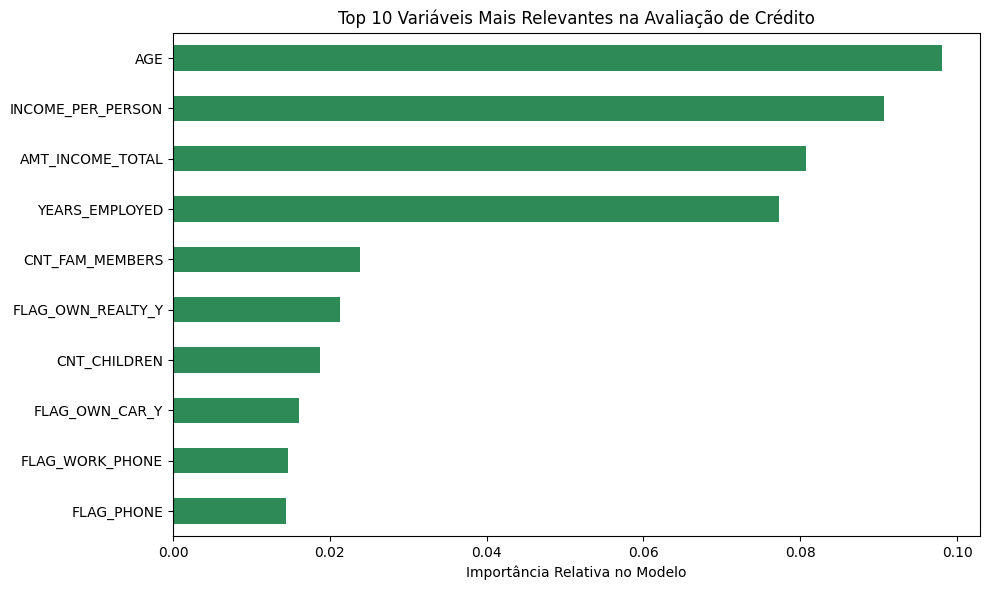

In [4]:
# Mapear importâncias e remover variáveis temporais redundantes brutas para clareza executiva
importances = pd.Series(modelo_rf.feature_importances_, index=X_train.columns)
importances_clean = importances.drop(index=['DAYS_BIRTH', 'DAYS_EMPLOYED', 'DAYS_EMPLOYED_CLEAN'], errors='ignore')

plt.figure(figsize=(10, 6))
importances_clean.nlargest(10).plot(kind='barh', color='seagreen')
plt.title('Top 10 Variáveis Mais Relevantes na Avaliação de Crédito')
plt.xlabel('Importância Relativa no Modelo')
plt.gca().invert_yaxis()
plt.tight_layout()
plt.show()

## **5. Implicações Práticas de Negócio**

A partir dos resultados e padrões identificados pelo modelo, a área de concessão de crédito do banco pode tomar as seguintes decisões estratégicas:

1. **Automação da Esteira de Crédito (Motor de Decisão):**
   * **Aprovação Expressa (Baixo Risco):** Clientes com baixíssima probabilidade de inadimplência possuem cartão aprovado instantaneamente nos canais digitais, otimizando a experiência do cliente (UX).
   * **Mesa de Análise Humana (Risco Intermediário):** Propostas com probabilidade moderada de risco são direcionadas para analistas humanos, destacando os pontos de atenção (ex.: baixa estabilidade no emprego ou renda per capita comprometida).
   * **Mitigação Preventiva de Perdas (Alto Risco):** Negativa automática ou oferta de limite reduzido com exigência de garantias adicionais.

2. **Indicadores Determinantes do Risco:**
   * A estabilidade no emprego (`YEARS_EMPLOYED`) e a capacidade financeira por membro da família (`INCOME_PER_PERSON`) revelaram-se preditores muito mais fortes para a adimplência do que a renda bruta declarada isoladamente.

## **6. Limitações**

1. Usar dados do mercado (Open Finance / SPC / Serasa): Como hoje só olhamos o histórico interno do cliente, consultar o endividamento dele em outros bancos e a pontuação de crédito externa vai nos dar uma visão muito mais completa do risco.

2. Acompanhar o modelo de perto: O comportamento dos consumidores muda com a economia (inflação, desemprego, mudanças de governo). Por isso, precisamos revisar e recalibrar o modelo a cada três meses para garantir que ele continue acertando.